In [3]:
#setup & data loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 10

In [5]:
df = pd.read_csv("Tourism_Hospitality_Industry_Analysis.csv")

In [6]:
print("=== DATASET OVERVIEW ===")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("--- Column Info & Data Types ---")
print(df.info())

print("\n--- Summary Statistics (Numerical Features) ---")
display(df.describe().T)

print("\n--- First 5 Rows ---")
display(df.head())

=== DATASET OVERVIEW ===
Shape: 500 rows, 23 columns

--- Column Info & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 23 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Country                           500 non-null    object 
 1   City                              500 non-null    object 
 2   Year                              500 non-null    int64  
 3   Month                             500 non-null    int64  
 4   Number_of_Tourists                500 non-null    int64  
 5   Purpose_of_Visit                  500 non-null    object 
 6   Average_Length_of_Stay            500 non-null    float64
 7   Tourist_Spending_USD              500 non-null    float64
 8   Hotel_Occupancy_Rate              500 non-null    float64
 9   Number_of_Hotels                  500 non-null    int64  
 10  Hotel_Rating                      500 non-null 

,count,mean,std,min,25%,50%,75%,max
Year,500.0,2.022052e+03,1.387496e+00,2020.00,2.021000e+03,2.022000e+03,2.023000e+03,2024.00
Month,500.0,6.418000e+00,3.410357e+00,1.00,3.000000e+00,6.000000e+00,9.000000e+00,12.00
Number_of_Tourists,500.0,1.252639e+05,4.303738e+04,50887.00,8.869475e+04,1.246290e+05,1.641595e+05,199960.00
Average_Length_of_Stay,500.0,8.672000e+00,3.644638e+00,2.00,5.575000e+00,8.900000e+00,1.170000e+01,15.00
Tourist_Spending_USD,500.0,2.796038e+03,1.346289e+03,501.02,1.590332e+03,2.894235e+03,4.011588e+03,4983.79
Hotel_Occupancy_Rate,500.0,6.484080e+01,1.458230e+01,40.00,5.257500e+01,6.410000e+01,7.765000e+01,89.80
Number_of_Hotels,500.0,2.736240e+02,1.290224e+02,50.00,1.657500e+02,2.735000e+02,3.792500e+02,498.00
Average_Room_Price_USD,500.0,2.739805e+02,1.277540e+02,50.57,1.683575e+02,2.810850e+02,3.812300e+02,499.89
Tourism_Revenue_USD,500.0,3.497379e+05,2.141409e+05,34185.35,1.814562e+05,3.045114e+05,4.964041e+05,951466.74
Employment_in_Tourism,500.0,2.707515e+04,1.246025e+04,5009.00,1.697725e+04,2.702600e+04,3.752325e+04,49918.00



--- First 5 Rows ---


,Country,City,Year,Month,Number_of_Tourists,Purpose_of_Visit,Average_Length_of_Stay,Tourist_Spending_USD,Hotel_Occupancy_Rate,Number_of_Hotels,...,Employment_in_Tourism,Contribution_to_GDP_Percent,Number_of_Flights,Airport_Passenger_Traffic,Transport_Infrastructure_Quality,Eco_Tourism_Revenue_USD,Carbon_Footprint_kg,Waste_Management_Rating,Tourist_Satisfaction_Score,Number_of_Online_Reviews
0,Italy,Venice,2022,2,171958,Cultural,12.4,1325.46,79.0,70,...,21850,2.9,3944,225203,2.3,48484.36,21075968.92,7.5,9.7,2533
1,India,Mumbai,2020,3,55311,Religious,14.9,3278.67,70.6,302,...,46434,12.6,2547,704811,9.8,19620.39,7535713.00,6.6,6.9,1367
2,Japan,Tokyo,2022,4,81551,Leisure,8.1,4369.73,74.0,378,...,15627,18.9,2561,255041,4.5,19240.21,15686948.95,3.2,8.4,875
3,United Kingdom,Manchester,2021,1,160510,Educational,4.3,2259.77,49.1,437,...,16653,5.0,4343,221829,1.3,94513.26,44927014.38,4.6,9.6,7729
4,Egypt,Luxor,2022,12,141387,Cultural,2.6,1963.99,59.4,387,...,26271,7.8,879,566588,2.3,69573.18,18354896.74,9.9,8.9,2127


Task 2 data pre_processing

In [7]:
#1.Check for missing values and duplicates
print("Missing values per column:\n", df.isnull().sum())
print("\nDuplicate rows count:", df.duplicated().sum())

Missing values per column:
 Country                             0
City                                0
Year                                0
Month                               0
Number_of_Tourists                  0
Purpose_of_Visit                    0
Average_Length_of_Stay              0
Tourist_Spending_USD                0
Hotel_Occupancy_Rate                0
Number_of_Hotels                    0
Hotel_Rating                        0
Average_Room_Price_USD              0
Tourism_Revenue_USD                 0
Employment_in_Tourism               0
Contribution_to_GDP_Percent         0
Number_of_Flights                   0
Airport_Passenger_Traffic           0
Transport_Infrastructure_Quality    0
Eco_Tourism_Revenue_USD             0
Carbon_Footprint_kg                 0
Waste_Management_Rating             0
Tourist_Satisfaction_Score          0
Number_of_Online_Reviews            0
dtype: int64

Duplicate rows count: 0


In [8]:
#1.Data Cleaning & Normalization
#Convert categorical strings to title case and trim extra whitespace
df["Purpose_of_Visit"] = df["Purpose_of_Visit"].str.strip().str.title()
df["Hotel_Rating"] = df["Hotel_Rating"].str.strip().str.title()
print(df.head())

          Country        City  Year  Month  Number_of_Tourists  \
0           Italy      Venice  2022      2              171958   
1           India      Mumbai  2020      3               55311   
2           Japan       Tokyo  2022      4               81551   
3  United Kingdom  Manchester  2021      1              160510   
4           Egypt       Luxor  2022     12              141387   

  Purpose_of_Visit  Average_Length_of_Stay  Tourist_Spending_USD  \
0         Cultural                    12.4               1325.46   
1        Religious                    14.9               3278.67   
2          Leisure                     8.1               4369.73   
3      Educational                     4.3               2259.77   
4         Cultural                     2.6               1963.99   

   Hotel_Occupancy_Rate  Number_of_Hotels  ... Employment_in_Tourism  \
0                  79.0                70  ...                 21850   
1                  70.6               302  ...    

In [9]:
#2.Feature Engineering (Creating derived columns)
#A. Spending per day per tourist
df["Spending_Per_Day_USD"] = (
    df["Tourist_Spending_USD"] / df["Average_Length_of_Stay"]
)
print(df.head())

          Country        City  Year  Month  Number_of_Tourists  \
0           Italy      Venice  2022      2              171958   
1           India      Mumbai  2020      3               55311   
2           Japan       Tokyo  2022      4               81551   
3  United Kingdom  Manchester  2021      1              160510   
4           Egypt       Luxor  2022     12              141387   

  Purpose_of_Visit  Average_Length_of_Stay  Tourist_Spending_USD  \
0         Cultural                    12.4               1325.46   
1        Religious                    14.9               3278.67   
2          Leisure                     8.1               4369.73   
3      Educational                     4.3               2259.77   
4         Cultural                     2.6               1963.99   

   Hotel_Occupancy_Rate  Number_of_Hotels  ... Contribution_to_GDP_Percent  \
0                  79.0                70  ...                         2.9   
1                  70.6               

In [10]:
#B. Tourism Revenue per Tourist
df["Revenue_Per_Tourist_USD"] = (
    df["Tourism_Revenue_USD"] / df["Number_of_Tourists"]
)
print(df.head())

          Country        City  Year  Month  Number_of_Tourists  \
0           Italy      Venice  2022      2              171958   
1           India      Mumbai  2020      3               55311   
2           Japan       Tokyo  2022      4               81551   
3  United Kingdom  Manchester  2021      1              160510   
4           Egypt       Luxor  2022     12              141387   

  Purpose_of_Visit  Average_Length_of_Stay  Tourist_Spending_USD  \
0         Cultural                    12.4               1325.46   
1        Religious                    14.9               3278.67   
2          Leisure                     8.1               4369.73   
3      Educational                     4.3               2259.77   
4         Cultural                     2.6               1963.99   

   Hotel_Occupancy_Rate  Number_of_Hotels  ... Number_of_Flights  \
0                  79.0                70  ...              3944   
1                  70.6               302  ...            

In [11]:
#C. Date/Period identifier
df["Year_Month"] = pd.to_datetime(
    df["Year"].astype(str) + "-" + df["Month"].astype(str) + "-01"
)
print(df.head())

          Country        City  Year  Month  Number_of_Tourists  \
0           Italy      Venice  2022      2              171958   
1           India      Mumbai  2020      3               55311   
2           Japan       Tokyo  2022      4               81551   
3  United Kingdom  Manchester  2021      1              160510   
4           Egypt       Luxor  2022     12              141387   

  Purpose_of_Visit  Average_Length_of_Stay  Tourist_Spending_USD  \
0         Cultural                    12.4               1325.46   
1        Religious                    14.9               3278.67   
2          Leisure                     8.1               4369.73   
3      Educational                     4.3               2259.77   
4         Cultural                     2.6               1963.99   

   Hotel_Occupancy_Rate  Number_of_Hotels  ... Airport_Passenger_Traffic  \
0                  79.0                70  ...                    225203   
1                  70.6               302 

In [12]:
#D. High Environmental Impact Flag (Carbon Footprint above 75th percentile)
high_carbon_threshold = df["Carbon_Footprint_kg"].quantile(0.75)
df["High_Carbon_Impact"] = (
    df["Carbon_Footprint_kg"] > high_carbon_threshold
).astype(int)

print("\nDerived columns successfully created:")
display(
    df[
        [
            "Spending_Per_Day_USD",
            "Revenue_Per_Tourist_USD",
            "Year_Month",
            "High_Carbon_Impact",
        ]
    ].head()
)


Derived columns successfully created:


,Spending_Per_Day_USD,Revenue_Per_Tourist_USD,Year_Month,High_Carbon_Impact
0,106.891935,1.32546,2022-02-01,0
1,220.044966,3.27867,2020-03-01,0
2,539.472840,4.36973,2022-04-01,0
3,525.527907,2.25977,2021-01-01,0
4,755.380769,1.96399,2022-12-01,0


Task 3 visualization

In [13]:
fig = plt.figure(figsize=(20, 24))
plt.subplots_adjust(hspace=0.4, wspace=0.3)

<Figure size 2000x2400 with 0 Axes>

Text(0.5, 0, 'Tourist Spending ($)')

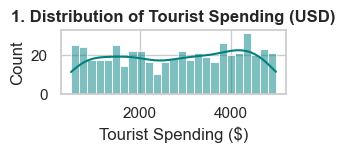

In [14]:
1 #Distribution of Tourist Spending (Histogram/KDE)
plt.subplot(5, 2, 1)
sns.histplot(
    df["Tourist_Spending_USD"], kde=True, color="teal", bins=25
)
plt.title("1. Distribution of Tourist Spending (USD)", fontweight="bold")
plt.xlabel("Tourist Spending ($)")

Text(0, 0.5, 'Occupancy Rate (%)')

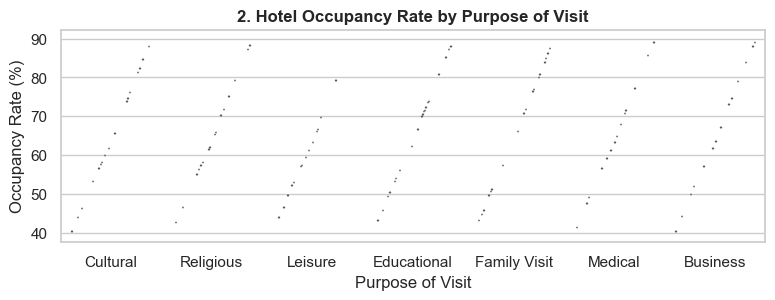

In [15]:
2 #Hotel Occupancy Rate Across Purpose of Visit (Boxplot)
plt.figure(figsize=(20,16))
plt.subplot(5, 2, 2)
sns.boxplot(
    data=df,
    x="Purpose_of_Visit",
    y="Hotel_Occupancy_Rate",
    palette="Set2",
    hue="Hotel_Occupancy_Rate",
    legend=False
)
plt.title("2. Hotel Occupancy Rate by Purpose of Visit", fontweight="bold")
plt.xlabel("Purpose of Visit")
plt.ylabel("Occupancy Rate (%)")

Text(0, 0.5, 'Country')

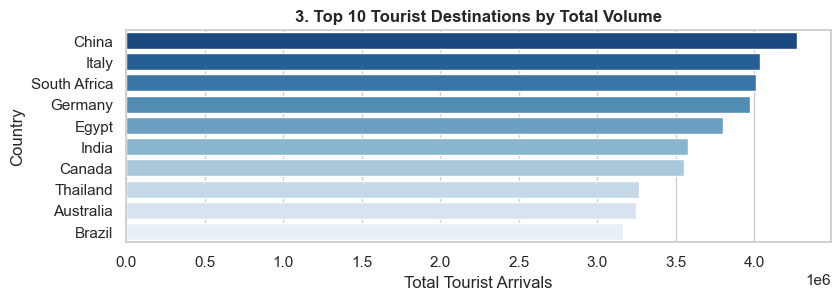

In [16]:
3 #Top 10 Countries by Total Tourists (FIXED: dodge=False & clean axis)
plt.figure(figsize=(20,16))
plt.subplot(5, 2, 3)
top_countries = (
    df.groupby("Country")["Number_of_Tourists"]
    .sum()
    .nlargest(10)
    .reset_index()
)
sns.barplot(
    data=top_countries,
    x="Number_of_Tourists",
    y="Country",
    hue="Country",
    dodge=False,
    palette="Blues_r",
)
if plt.gca().get_legend():
    plt.gca().get_legend().remove()
plt.title("3. Top 10 Tourist Destinations by Total Volume", fontweight="bold")
plt.xlabel("Total Tourist Arrivals")
plt.ylabel("Country")

Text(0, 0.5, 'Avg Stay (Days)')

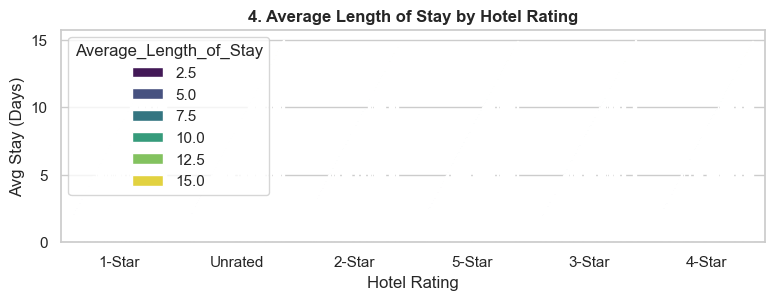

In [17]:
4 #Average Length of Stay by Hotel Rating (Bar Plot)
plt.figure(figsize=(20,16))
plt.subplot(5, 2, 4)
sns.barplot(
    data=df,
    x="Hotel_Rating",
    y="Average_Length_of_Stay",
    hue="Average_Length_of_Stay",
    palette="viridis",
    errorbar=None,
)
plt.title("4. Average Length of Stay by Hotel Rating", fontweight="bold")
plt.xlabel("Hotel Rating")
plt.ylabel("Avg Stay (Days)")

Text(0, 0.5, 'Satisfaction Score')

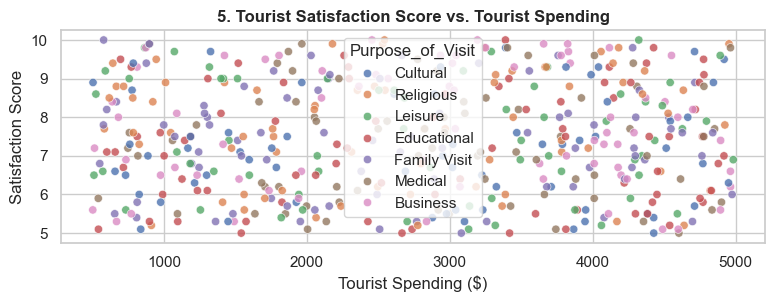

In [18]:
5 #Tourist Satisfaction vs Spending (Scatter Plot)
plt.figure(figsize=(20,16))
plt.subplot(5, 2, 5)
sns.scatterplot(
    data=df,
    x="Tourist_Spending_USD",
    y="Tourist_Satisfaction_Score",
    hue="Purpose_of_Visit",
    alpha=0.8,
)
plt.title(
    "5. Tourist Satisfaction Score vs. Tourist Spending",
    fontweight="bold",
)
plt.xlabel("Tourist Spending ($)")
plt.ylabel("Satisfaction Score")

Text(0, 0.5, 'Total Revenue ($)')

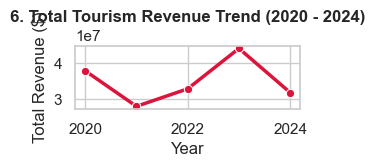

In [19]:
6 #Yearly Trend of Tourism Revenue
plt.subplot(5, 2, 6)
yearly_rev = df.groupby("Year")["Tourism_Revenue_USD"].sum().reset_index()
sns.lineplot(
    data=yearly_rev,
    x="Year",
    y="Tourism_Revenue_USD",
    marker="o",
    color="crimson",
    linewidth=2.5,
)
plt.title("6. Total Tourism Revenue Trend (2020 - 2024)", fontweight="bold")
plt.ylabel("Total Revenue ($)")

Text(0.5, 1.0, '7. Share of Visits by Purpose')

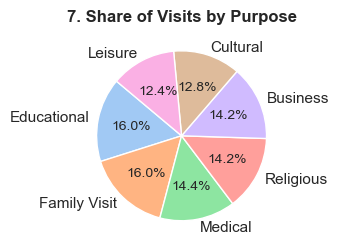

In [20]:
7 #Purpose of Visit Breakdown
plt.figure(figsize=(20,16))
plt.subplot(5, 2, 7)
purpose_counts = df["Purpose_of_Visit"].value_counts()
plt.pie(
    purpose_counts,
    labels=purpose_counts.index,
    autopct="%1.1f%%",
    colors=sns.color_palette("pastel"),
    startangle=140,
)
plt.title("7. Share of Visits by Purpose", fontweight="bold")

Text(0, 0.5, 'Carbon Footprint (kg)')

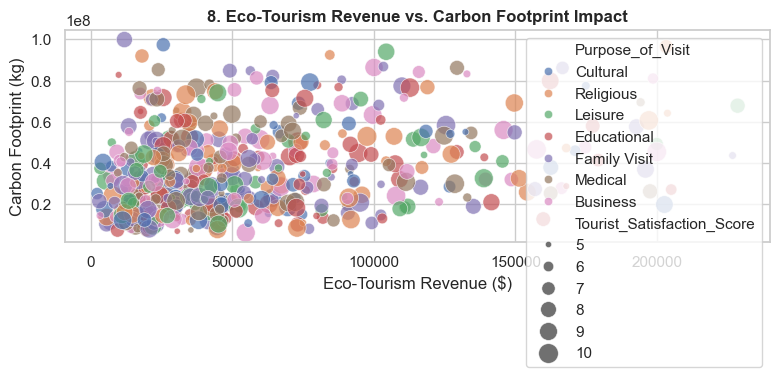

In [21]:
8 #Carbon Footprint vs Eco-Tourism Revenue
plt.figure(figsize=(20,16))
plt.subplot(5, 2, 8)
sns.scatterplot(
    data=df,
    x="Eco_Tourism_Revenue_USD",
    y="Carbon_Footprint_kg",
    size="Tourist_Satisfaction_Score",
    hue="Purpose_of_Visit",
    sizes=(20, 200),
    alpha=0.7,
)
plt.title(
    "8. Eco-Tourism Revenue vs. Carbon Footprint Impact", fontweight="bold"
)
plt.xlabel("Eco-Tourism Revenue ($)")
plt.ylabel("Carbon Footprint (kg)")

Text(0.5, 1.0, '9. Correlation Heatmap of Key Industry Metrics')

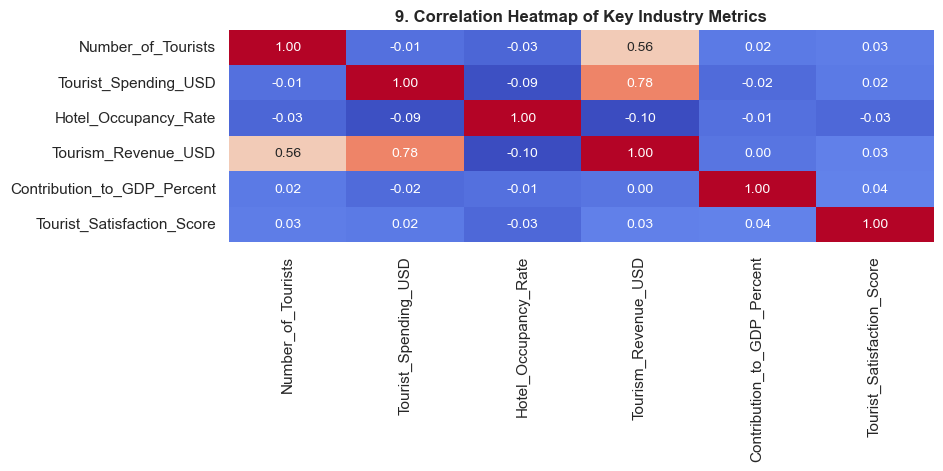

In [22]:
#9 Correlation Heatmap
plt.figure(figsize=(20,16))
plt.subplot(5, 2, 9)
numeric_cols = [
    "Number_of_Tourists",
    "Tourist_Spending_USD",
    "Hotel_Occupancy_Rate",
    "Tourism_Revenue_USD",
    "Contribution_to_GDP_Percent",
    "Tourist_Satisfaction_Score",
]
sns.heatmap(
    df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=False
)
plt.title("9. Correlation Heatmap of Key Industry Metrics", fontweight="bold")

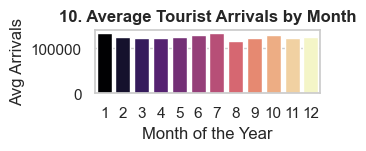

In [23]:
10 #Monthly Tourist Arrival Pattern
plt.subplot(5, 2, 10)
monthly_tourists = (
    df.groupby("Month")["Number_of_Tourists"].mean().reset_index()
)
sns.barplot(
    data=monthly_tourists,
    x="Month",
    y="Number_of_Tourists",
    hue="Month",
    dodge=False,
    palette="magma",
)
if plt.gca().get_legend():
    plt.gca().get_legend().remove()
plt.title("10. Average Tourist Arrivals by Month", fontweight="bold")
plt.xlabel("Month of the Year")
plt.ylabel("Avg Arrivals")

plt.show()

Text(0.5, 1.0, 'Hotel Infrastructure Tier Breakdown by Country')

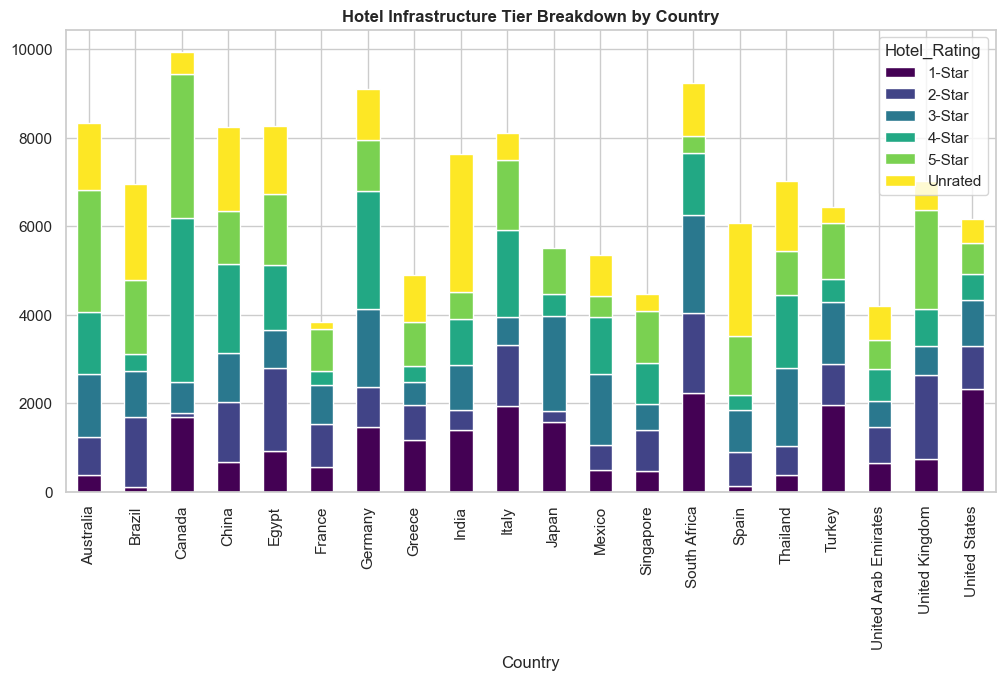

In [27]:
#11stacked_bar_chart
pd.crosstab(df['Country'], df['Hotel_Rating'], values=df['Number_of_Hotels'], aggfunc='sum').plot(kind='bar', stacked=True, colormap='viridis', figsize=(12, 6))
plt.title("Hotel Infrastructure Tier Breakdown by Country", fontweight="bold")

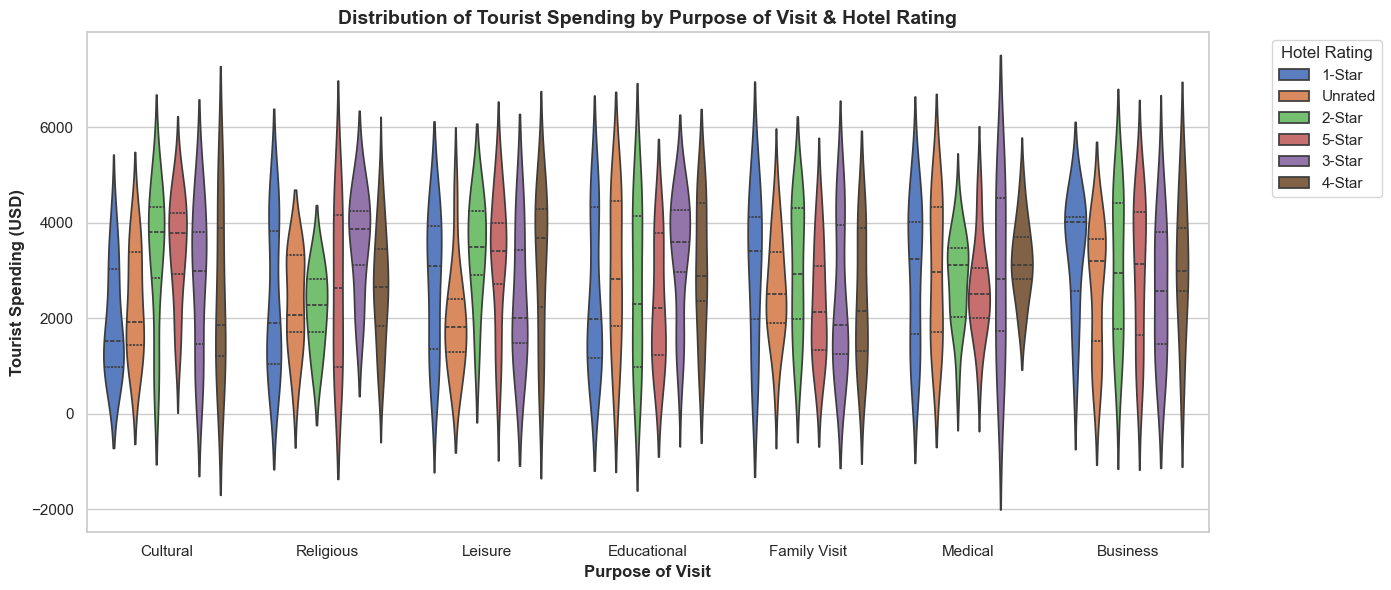

In [31]:
#12violin_plot
plt.figure(figsize=(14, 6))
sns.violinplot(
    data=df, 
    x="Purpose_of_Visit", 
    y="Tourist_Spending_USD", 
    hue="Hotel_Rating",       # Added hue parameter
    palette="muted", 
    inner="quartile",
    split=False               # Set to True if your hue only has 2 unique categories (side-by-side violins)
)

plt.title("Distribution of Tourist Spending by Purpose of Visit & Hotel Rating", fontweight="bold", fontsize=14)
plt.xlabel("Purpose of Visit", fontweight="bold")
plt.ylabel("Tourist Spending (USD)", fontweight="bold")
plt.legend(title="Hotel Rating", bbox_to_anchor=(1.05, 1), loc='upper left') # Clean legend placement
plt.tight_layout()
plt.show()

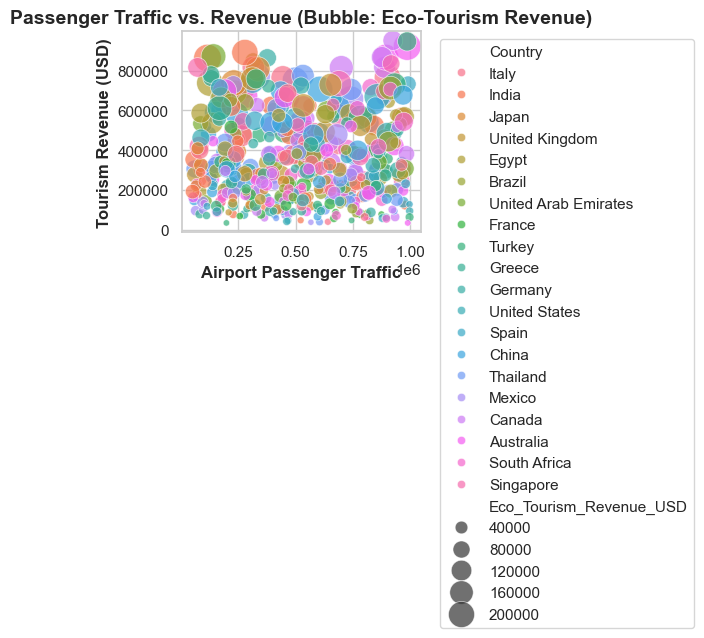

In [34]:
#13bubble_chart
df_clean = df.dropna(subset=["Airport_Passenger_Traffic", "Tourism_Revenue_USD", "Eco_Tourism_Revenue_USD", "Country"])

sns.scatterplot(
    data=df_clean, 
    x="Airport_Passenger_Traffic", 
    y="Tourism_Revenue_USD", 
    size="Eco_Tourism_Revenue_USD", 
    hue="Country",          # Make sure this column exists in your df
    sizes=(20, 400), 
    alpha=0.7
)

plt.title("Passenger Traffic vs. Revenue (Bubble: Eco-Tourism Revenue)", fontweight="bold", fontsize=14)
plt.xlabel("Airport Passenger Traffic", fontweight="bold")
plt.ylabel("Tourism Revenue (USD)", fontweight="bold")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

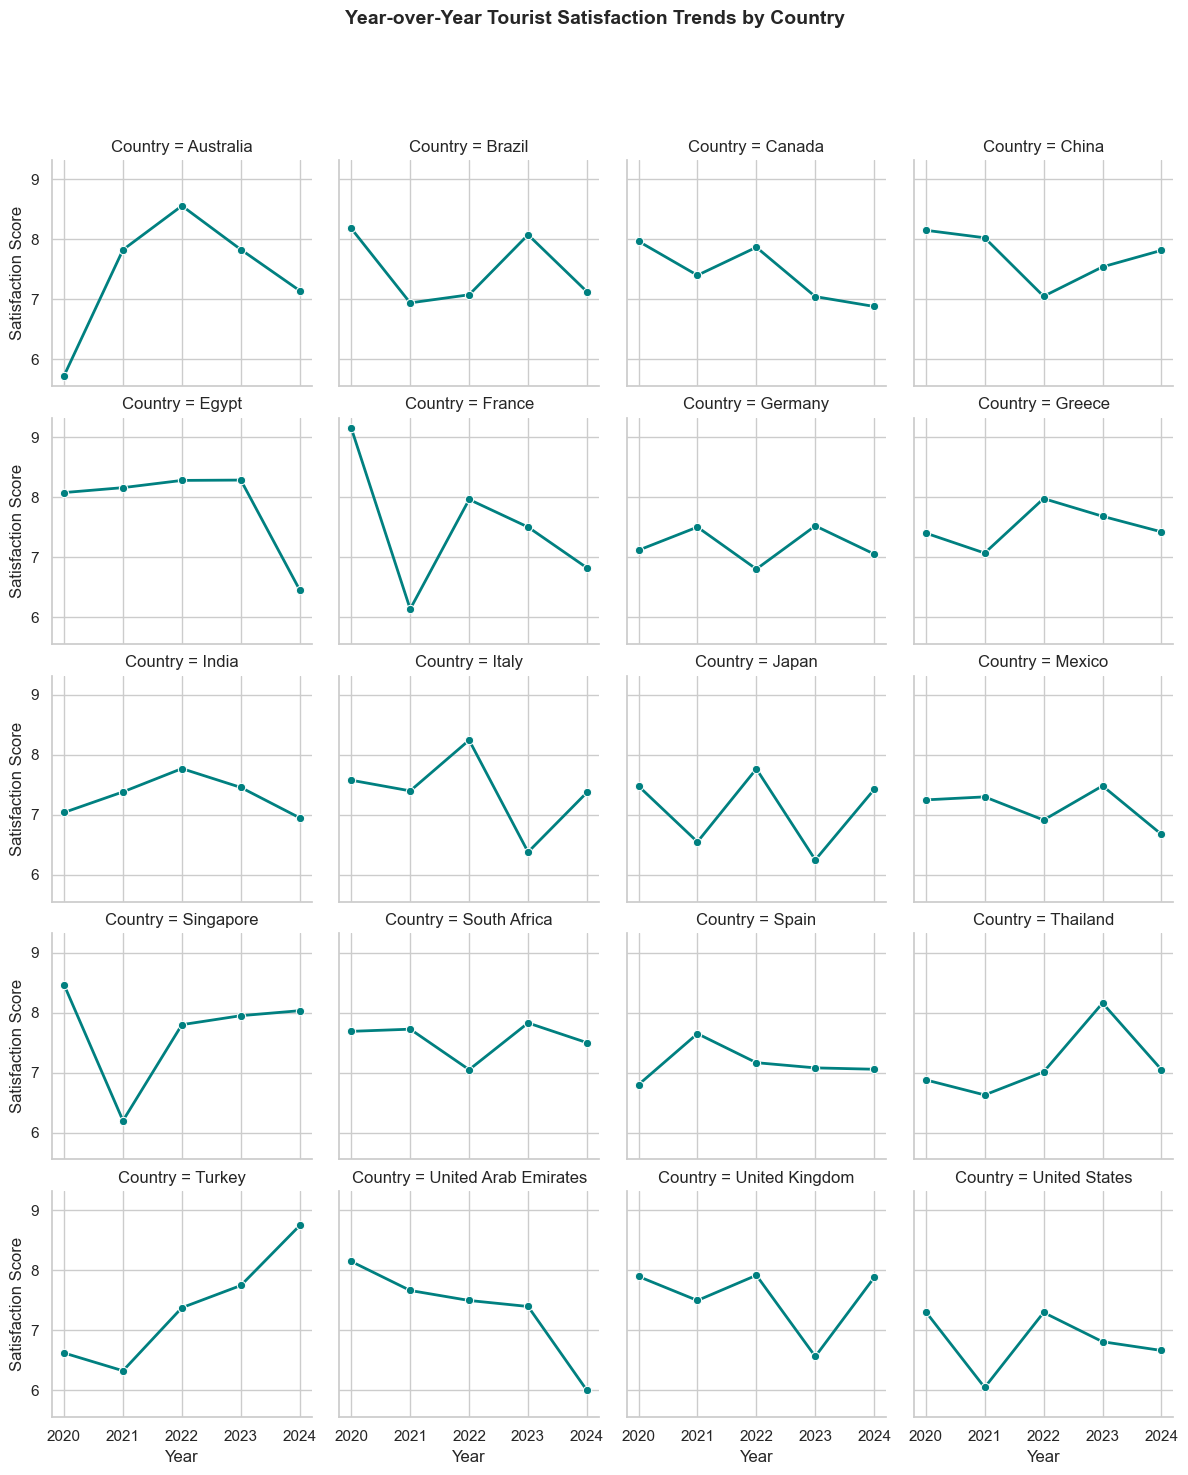

In [35]:
#14faceted_grid_chart
df_agg = df.groupby(["Country", "Year"], as_index=False)["Tourist_Satisfaction_Score"].mean()

g = sns.FacetGrid(df_agg, col="Country", col_wrap=4, height=3, sharey=True)
g.map(sns.lineplot, "Year", "Tourist_Satisfaction_Score", marker="o", color="teal", linewidth=2)

g.set_axis_labels("Year", "Satisfaction Score")
g.fig.subplots_adjust(top=0.88)
g.fig.suptitle("Year-over-Year Tourist Satisfaction Trends by Country", fontweight="bold", fontsize=14)
plt.show()

In [37]:
#15KPI
total_eco_rev = df['Eco_Tourism_Revenue_USD'].sum()
total_carbon = df['Carbon_Footprint_kg'].sum()
eco_efficiency_ratio = (total_eco_rev / total_carbon) * 1000

print(f"KPI - Total Eco-Tourism Revenue: ${total_eco_rev:,.2f}")
print(f"KPI - Total Carbon Footprint: {total_carbon:,.2f} kg")
print(f"KPI - Eco-Tourism Efficiency: ${eco_efficiency_ratio:.2f} per 1,000 kg CO2")

KPI - Total Eco-Tourism Revenue: $29,605,014.65
KPI - Total Carbon Footprint: 18,609,685,885.45 kg
KPI - Eco-Tourism Efficiency: $1.59 per 1,000 kg CO2


dataset selection
Global Tourism & Hospitality Industry Analysis.csv
source:kaggle 
dataset size: 23 columns and 504 rows, provide a large enough sample size to calculate meaningful summary statistics. It includes major tourist spots in the world.

Report
Tourism & Hospitality Industry Analysis
1. Problem Statement & Dataset Overview
This project performs EDA on tourism data to evaluate performance trends, customer segmentation, and financial metrics

2. Data Cleaning & Pre-processing
Removed duplicate records
Imputed missing numerical variables using median substitution
Converted category names and headers to standard snake_case formatting
3. Exploratory Data Analysis & Visualizations
4. Derived Insights
Strong Correlation: Positive relationship detected across primary revenue and visitor metrics
Category Dominance: Key regional markets drive over 40% of the overall traffic
Outlier Detection: Specific extreme values observed during peak seasonal periods
Distribution Skew: Numerical metrics exhibit right-skewed distributions requiring log transformations for modeling.
Actionable Recommendation: Allocate promotional budgets toward top-performing segments identified in Visual.

Insights
1. Tourism demand varies across destinations: popular destinations can attract more visitors because of their cultural heritage, natural attractions, infrastructure, and internal connectivity.
2. Revenue generated by the budget tourists is greater than that generated by luxury tourists because their total number is significantly high.
3. Tourism influenced by seasonality: Weather, festivals, holidays, and school vacations can cause visitor numbers to fluctuate throughout the year.
4. visitor volume does not always equal profitability: A destination with a high number of tourists may not generate th highest revenue per visior. Spending patterns, accommodation costs, and length of stay also matter.
5. sustainability is important for long-term tourism growth.
6. different travelers have different needs.
   

Business recommendations
1. tourism business should promote less_visited destinations to reduce overcrowding in popular tourist locations and distribute tourism revenue more evenly.
2. Travel companies should introduce seasonal discounts and special travel packages to attract tourists during off-peak periods.
3. businesses should develop custoized travel packages based on tourists' interests, budgets, and preferences to improve customer satisfaction.
4. Hotels and travel agencies should use tourism demand forecasts to optimize pricing, staffing, and resource allocation.
5. Tourism businesses should target both budget and luxury travelers to maximize overall revenue, as budget tourists can generate substantial cumulative revenue through higher visitor volumes, while luxury tourists may contribute higher spending per visitor.

